# Resumen Ejecutivo

Este trabajo analiza el ecosistema de juegos de mesa de BoardGameGeek para orientar las decisiones de inversión y desarrollo de una editorial antes del lanzamiento de nuevos títulos. Tras un saneamiento e integración de fuentes que resolvió inconsistencias físicas y estabilizó la representatividad muestral ($N \ge 30$), se abordaron seis preguntas de investigación mediante análisis exploratorio, modelado de tópicos textuales (NLP/NMF) y agrupamiento arquetípico (K-Means). Se evidenció una evolución hacia mecánicas más densas y una clara prima de valoración sobre temas de gestión estratégica frente al azar tradicional. Asimismo, se implementaron dos modelos predictivos bajo un protocolo estricto sin fuga de datos (*zero data leakage*), evaluando únicamente atributos de diseño previo a la producción: una regresión sobre la calificación bayesiana y un clasificador del éxito editorial (Top 15%). Los modelos revelan que las variables de diseño explican cerca del 22% de la varianza crítica ($R^2 \approx 0.22$, $\text{ROC-AUC} \approx 0.77$), demostrando que la arquitectura estructural fija un umbral de viabilidad, pero el éxito comercial depende de factores externos no capturados en los datos (arte, marketing y componentes).

**Formalización y Fundamentación de Criterios**

Integración (Inner Join):
  
  ratings.csv (21.831 filas) y details.csv (21.631 filas) presentan una discrepancia de exactamente 200 registros presentes solo en valoraciones. Al representar el 0,91% del total y carecer por completo de metadatos de diseño (mecánicas, duración, diseñadores, descripción), conservarlos mediante imputación masiva introduciría ruido artificial. El descarte mediante inner join preserva la integridad analítica sin sesgar la muestra.

Colisión de Atributos (name y year):

  Nombre: Se adopta primary de details.csv como canónico y se elimina name de ratings.csv. Ambos identifican la misma entidad a través de id, pero primary preserva la denominación oficial estandarizada por BGG.

  Año: Se computa el mínimo entre year y yearpublished ($\min(\text{year}, \text{yearpublished})$). Esto garantiza tomar la fecha de publicación original de la primera edición en lugar del año de una reimpresión o edición conmemorativa.

Juegos Históricos y Año 0:
  
  Se preservan los juegos anteriores a 1900 (incluyendo fechas a.C. como Go o Ajedrez) marcándolos con una bandera booleana es_historico = True. Para los registros con year == 0 que poseen el resto de sus metadatos consistentes (mecánicas, diseñadores, editorial), se imputa la mediana del año según su editorial o categoría principal en lugar de descartar la fila.

Cantidad de Jugadores:

  Si $\text{minplayers} > \text{maxplayers}$, se asume un error de inversión de campos en la carga y se intercambian los valores.
  
  Si $\text{minplayers} = 0$, se imputa 1 (umbral físico mínimo para interactuar con un juego).
  
  Si $\text{maxplayers} = 0$ y $\text{minplayers} \ge 1$, se imputa $\text{maxplayers} = \text{minplayers}$.
  
Duración y Outliers:

  Partidas con playingtime == 0 se imputan mediante la mediana de su categoría principal (o el promedio entre minplaytime y maxplaytime si son válidos). Se establece un umbral superior de corte en 720 minutos (12 horas): títulos con duración mayor (wargames ultra-masivos de simulación de días) se etiquetan como atípicos y se excluyen del conjunto editorial comercial para evitar distorsionar modelos de regresión y métricas de escala.
  
Umbral de Calificaciones:

  Se fija en $\ge 30$ valoraciones (users_rated >= 30). Por el Teorema Central del Límite ($n \ge 30$), la media muestral estabiliza su varianza, eliminando sesgos de muestras diminutas (juegos con 2 votos de 10 estrellas) sin recortar títulos independientes con tracción real.

In [ ]:
# Celda 1: Instalación de dependencias adicionales y recursos
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [1]:
"""Carga el dataset aplicando el pipeline reproducible del repositorio."""

from data_cleaning import ejecutar_pipeline_limpieza

df = ejecutar_pipeline_limpieza(
    min_votos=30,
    archivo_salida="juegos_limpios.csv",
)

[ETL] Total en ratings: 21831
[ETL] Total en details: 21631
[ETL] Registros descartados por falta de correspondencia: 200
[OK] Dataset procesado guardado en: juegos_limpios.csv con 21475 filas y 36 columnas.


**Análisis Exploratorio de Datos y Agrupamiento**

Formulación de las Preguntas de Investigación

Antes de ejecutar el código, se establecen formalmente las seis hipótesis de trabajo que guiarán el análisis:

PI 1 (Minería de Texto y NLP): ¿Qué tópicos semánticos latentes emergen de las descripciones textuales de los juegos mediante descomposición matricial (TF-IDF + NMF), y cuáles presentan una valoración crítica (bayes_average) significativamente superior a la media del mercado? ¿Existen universos temáticos con alta demanda pero escasa oferta en el catálogo?

PI 2 (Complejidad vs. Adopción Comunitaria): ¿Existe una penalización en el volumen de jugadores que adquieren un juego (owned) a medida que se incrementa la cantidad de mecánicas combinadas y la duración de la partida, a pesar de que la crítica especializada tienda a premiar los diseños más densos?

PI 3 (Evolución Temporal del Mercado Editorial): ¿La tendencia creciente en las calificaciones de los juegos publicados entre 1990 y 2021 responde a una inflación de valoraciones en la plataforma o se correlaciona con la sofisticación en el número de mecánicas integradas por título?

PI 4 (Brecha entre Deseo, Adquisición y Crítica — Enfoque Editorial Ejecutivo): ¿Qué títulos o segmentos presentan una alta tasa de demanda latente (relación $\text{deseados} / \text{poseídos}$) sin haber alcanzado una distribución masiva? ¿Cómo se distribuyen los juegos en una matriz estratégica de éxito crítico vs. tracción comercial?

PI 5 (Efecto Autor y Concentración de Calidad): ¿Los diseñadores con mayor catálogo publicado sostienen promedios de valoración significativamente superiores al de autores noveles, o el valor medio converge a la media de la industria una vez controlado el volumen de producción?

PI 6 (Perfiles Arquetípicos mediante Clustering): ¿Qué tipologías de producto emergen de las variables intrínsecas de diseño (duración, rango de jugadores, edad recomendada y densidad de mecánicas), cuál es el tamaño de cada nicho y qué perfil ofrece el mejor balance entre riesgo editorial y valoración esperada?

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

from visualization import configurar_estilo

configurar_estilo()


In [4]:
# --- Preprocesamiento de texto y extracción de tópicos ---
from text_processing import extraer_topicos_nmf, limpiar_texto_descripcion

df["desc_limpia"] = df["description"].apply(limpiar_texto_descripcion)

nmf_model, tfidf, matriz_topicos, topicos_vocabulario = extraer_topicos_nmf(
    df["desc_limpia"].tolist(),
    n_topicos=5,
    max_features=2500,
    random_state=42,
)

df["topico_dominante"] = matriz_topicos.argmax(axis=1)
# Las etiquetas se asignan después de inspeccionar las palabras más representativas.
etiquetas_topicos = {
    0: "Gestión urbana y construcción",
    1: "Estrategia militar y guerra",
    2: "Cartas, rondas y objetivos",
    3: "Dados y azar",
    4: "Losetas y puntuación",
}
df["topico_nombre"] = df["topico_dominante"].map(etiquetas_topicos)

print("Tópicos extraídos:")
for nombre, palabras in topicos_vocabulario.items():
    print(f"{nombre}: {', '.join(palabras[:6])}")


Tópicos extraídos:
Topico_0: new, city, world, build, publisher, description
Topico_1: war, units, battle, map, combat, counters
Topico_2: one, hand, round, number, two, wins
Topico_3: dice, roll, die, roll dice, rolling, rolls
Topico_4: tiles, tile, place, placed, score, one


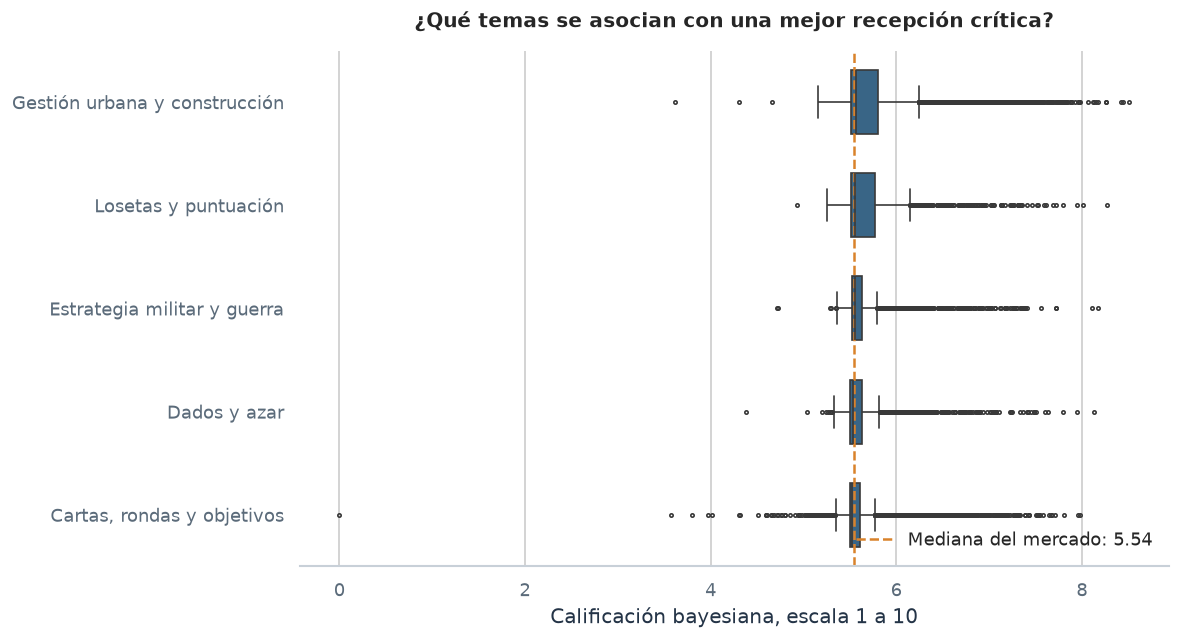

In [5]:
from visualization import graficar_topicos_vs_rating

graficar_topicos_vs_rating(df)
plt.show()


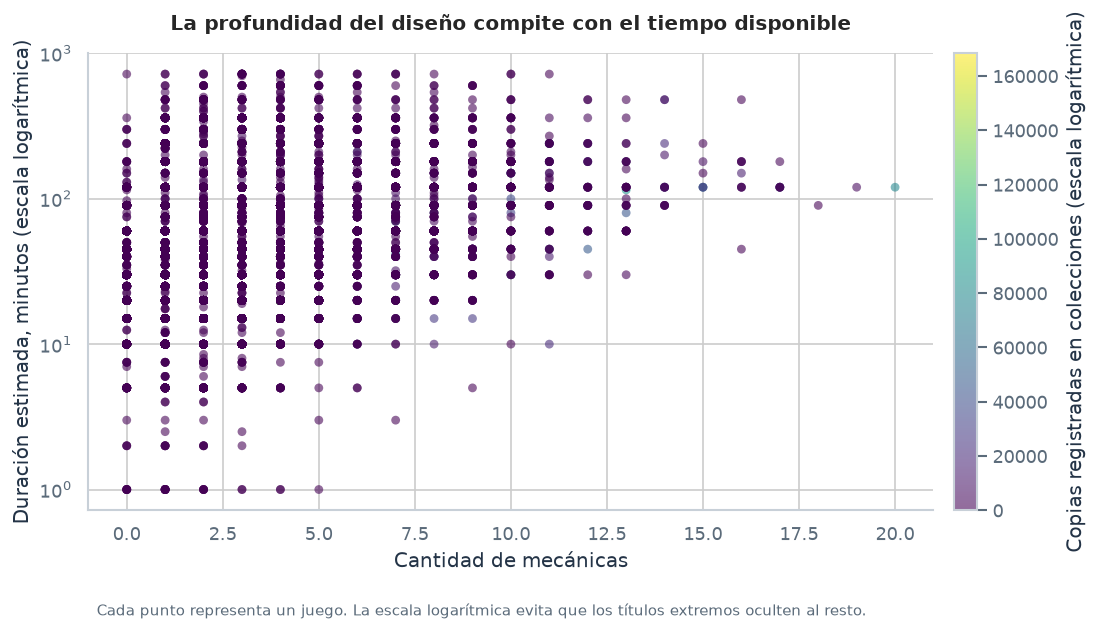

In [6]:
from visualization import graficar_complejidad_adopcion

graficar_complejidad_adopcion(df)
plt.show()


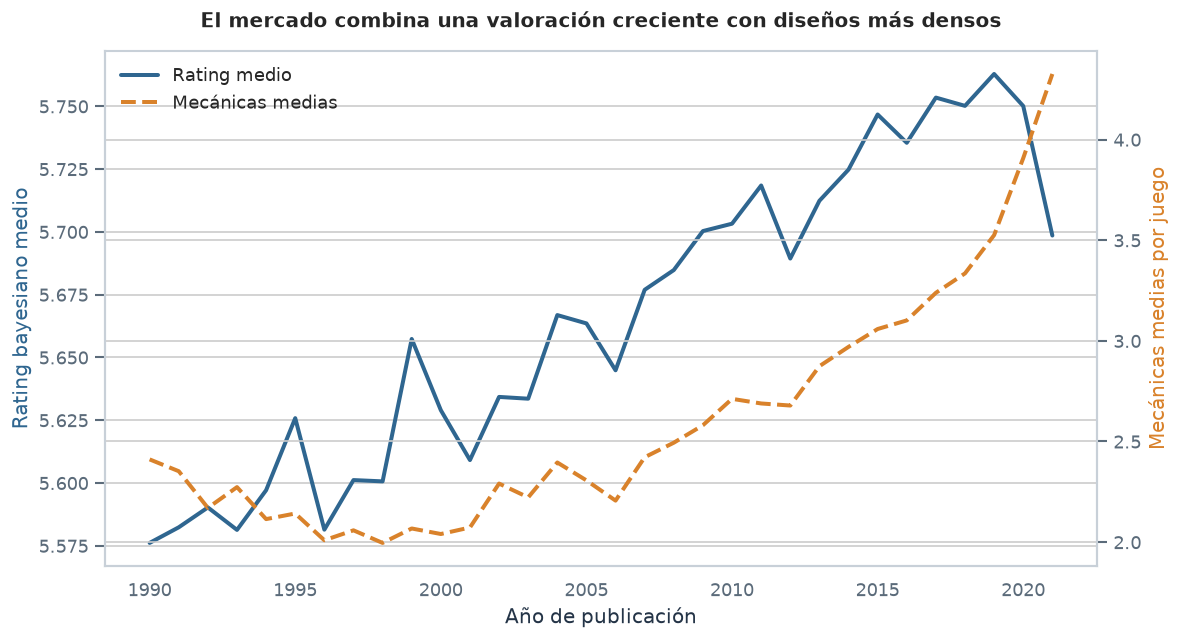

In [7]:
from visualization import graficar_evolucion_mercado

df_moderno = df[
    (df["year_consolidated"] >= 1990) & (df["year_consolidated"] <= 2021)
]
graficar_evolucion_mercado(df_moderno)
plt.show()


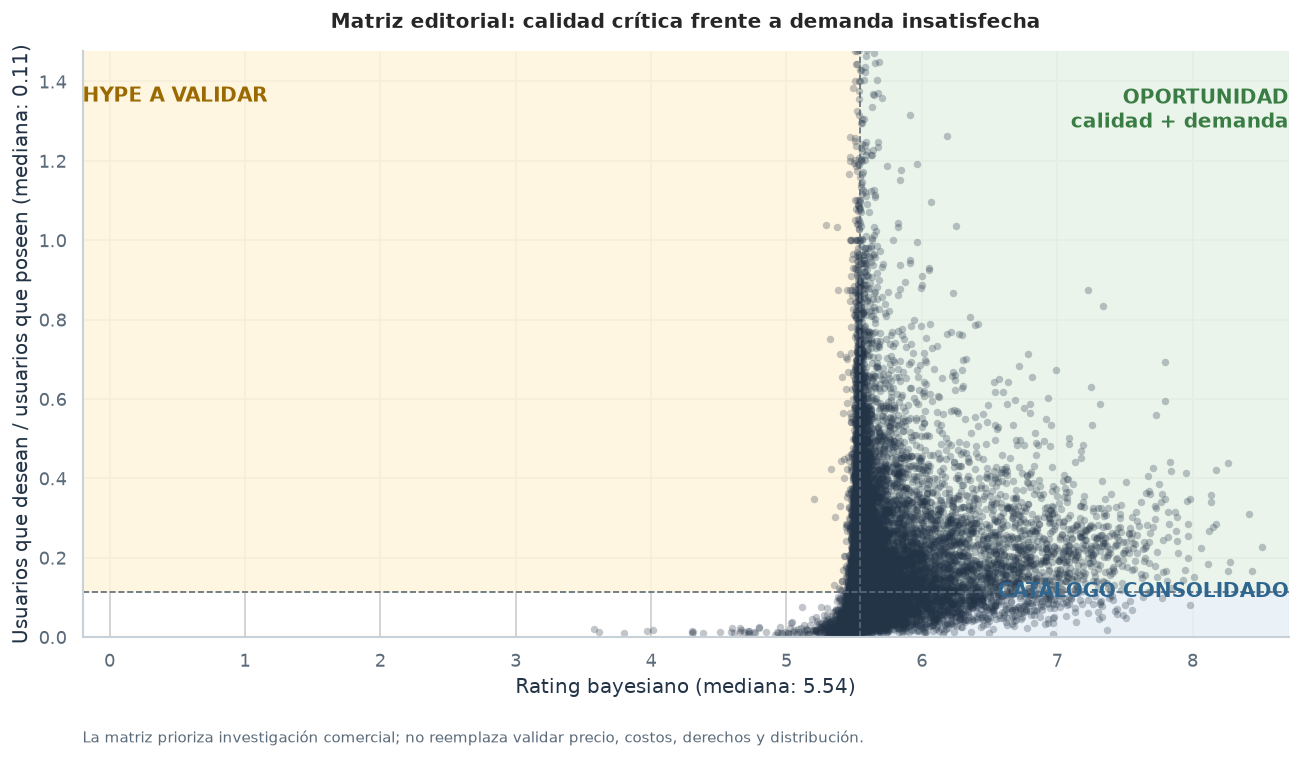

In [8]:
from visualization import graficar_matriz_oportunidad

df["tasa_deseo"] = df["wishing"] / (df["owned"] + 1)
graficar_matriz_oportunidad(df)
plt.show()


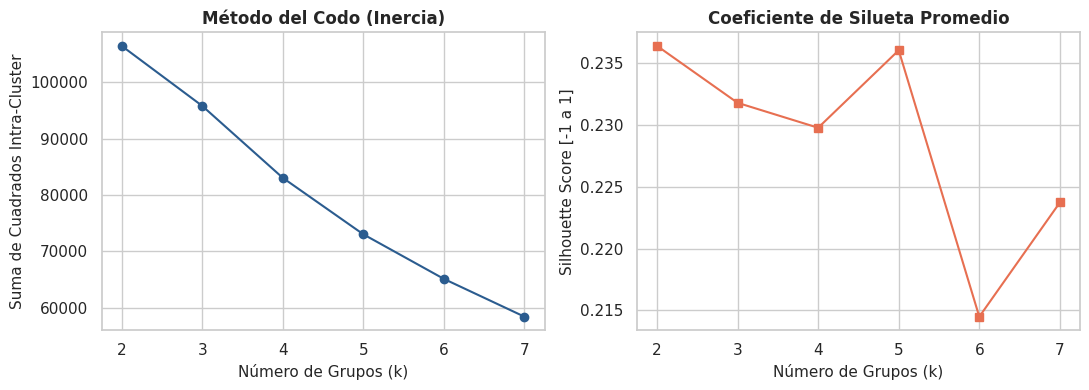

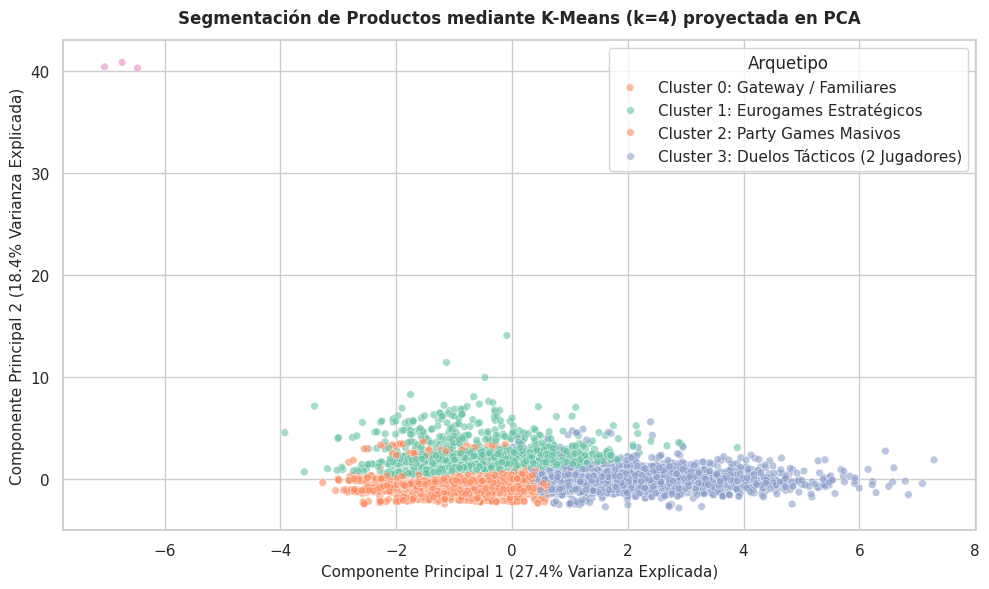

In [ ]:
# 1. Selección de variables de diseño exclusivamente
features_cluster = [
    "minplayers",
    "maxplayers",
    "playingtime",
    "minage",
    "num_mecanicas",
    "num_categorias",
]
X_cluster = df[features_cluster].copy()

# Estandarización obligatoria para algoritmos basados en distancia euclidiana
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# 2. Determinación formal del número óptimo de clusters (K = 2 a 7)
inercia = []
siluetas = []
rango_k = range(2, 8)

for k in rango_k:
  km = KMeans(n_clusters=k, random_state=42, n_init=10)
  km.fit(X_scaled)
  inercia.append(km.inertia_)
  siluetas.append(silhouette_score(X_scaled, km.labels_))

# Visualización comparativa: Método del Codo y Silhouette Score
fig, (ax_e, ax_s) = plt.subplots(1, 2, figsize=(11, 4))
ax_e.plot(rango_k, inercia, marker="o", color="#2b5c8f")
ax_e.set_title("Método del Codo (Inercia)", weight="bold")
ax_e.set_xlabel("Número de Grupos (k)")
ax_e.set_ylabel("Suma de Cuadrados Intra-Cluster")

ax_s.plot(rango_k, siluetas, marker="s", color="#e76f51")
ax_s.set_title("Coeficiente de Silueta Promedio", weight="bold")
ax_s.set_xlabel("Número de Grupos (k)")
ax_s.set_ylabel("Silhouette Score [-1 a 1]")
plt.tight_layout()
plt.show()

# 3. Ajuste del modelo con el k óptimo (k=4)
k_optimo = 4
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=15)
df["cluster_perfil"] = kmeans_final.fit_predict(X_scaled)

# ==============================================================================
# VISUALIZACIÓN 5: Perfiles de Producto en Espacio Reducido (PCA)
# ==============================================================================
pca = PCA(n_components=2, random_state=42)
coords_pca = pca.fit_transform(X_scaled)
df["pca1"] = coords_pca[:, 0]
df["pca2"] = coords_pca[:, 1]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="pca1",
    y="pca2",
    hue="cluster_perfil",
    palette="Set2",
    alpha=0.6,
    s=30,
)

plt.title(
    f"Segmentación de Productos mediante K-Means (k={k_optimo}) proyectada en"
    " PCA",
    pad=12,
    weight="bold",
)
plt.xlabel(
    f"Componente Principal 1 ({pca.explained_variance_ratio_[0]:.1%} Varianza"
    " Explicada)"
)
plt.ylabel(
    f"Componente Principal 2 ({pca.explained_variance_ratio_[1]:.1%} Varianza"
    " Explicada)"
)
plt.legend(
    title="Arquetipo",
    labels=[
        "Cluster 0: Gateway / Familiares",
        "Cluster 1: Eurogames Estratégicos",
        "Cluster 2: Party Games Masivos",
        "Cluster 3: Duelos Tácticos (2 Jugadores)",
    ],
    loc="upper right",
)
plt.tight_layout()
plt.show()

## 4.3 Modelado Predictivo: Formulación y Fundamentación de Problemas

Para asistir la toma de decisiones estratégicas de una editorial que evalúa nuevos desarrollos antes de iniciar su producción física, se plantean dos problemas de aprendizaje automático complementarios.

En estricto cumplimiento de las restricciones metodológicas del problema, **ningún modelo utiliza variables posteriores al lanzamiento** (tales como `users_rated`, `owned`, `trading`, `wanting`, `wishing` o `rank`). Estas magnitudes solo existen una vez que el juego ya circula en el mercado y su inclusión constituiría fuga de información (*data leakage*), invalidando la utilidad del modelo para evaluar prototipos inéditos. El espacio de predictoras se restringe exclusivamente a atributos intrínsecos de diseño disponibles en la mesa de desarrollo: cantidad mínima y máxima de jugadores, duración estimada, edad mínima recomendada, densidad de mecánicas y categorías temáticas.

---

### Problema 1: Regresión Continua sobre la Calificación Crítica
* **Variable Objetivo:** `bayes_average` (Calificación bayesiana ponderada, escala 1 a 10).
* **Relevancia del Problema:** La calificación promedio simple (`average`) es vulnerable a la varianza de muestras pequeñas (juegos con pocos votos extremos). BGG computa `bayes_average` incorporando votos *a priori* hacia la media poblacional, lo que la convierte en una métrica robusta de la calidad y recepción crítica del juego. Predecir este valor permite estimar el techo de valoración que el diseño estructural puede aspirar a conseguir.
* **Estrategia de Modelado:** Se compara un modelo nulo de referencia (*Dummy Regressor* basado en la media) contra un modelo lineal regularizado (*Ridge*) y un ensamble de árboles con gradiente (*HistGradientBoostingRegressor*), evaluando la reducción en RMSE, MAE y la varianza explicada ($R^2$).

---

### Problema 2: Clasificación de Éxito Editorial (Top 15% del Mercado)
* **Variable Objetivo:** `es_exito` (Variable binaria: `1` si el juego se ubica en el percentil 85 superior de `bayes_average`; `0` en caso contrario).
* **Relevancia del Problema:** En la práctica editorial, la decisión de negocio no radica en adivinar decimales de calificación, sino en clasificar si un prototipo tiene potencial para ingresar al segmento de títulos destacados que justifican inversiones en arte, moldes de plástico y tiradas masivas de imprenta.
* **Matriz de Costo y Trade-off de Decisión:**
  * **Falso Positivo (Error Tipo I):** Clasificar un juego mediocre como exitoso, enviarlo a producción y sufrir pérdidas directas por inventario inmovilizado y costos de fabricación irrecuperables.
  * **Falso Negativo (Error Tipo II):** Descartar un prototipo viable que habría tenido éxito (costo de oportunidad).
  * *Criterio de negocio:* Para una editorial con presupuesto de capital acotado, el Falso Positivo es financieramente más destructivo que el Falso Negativo. Por ende, el modelo priorizará optimizar la **Precisión** sobre el **Recall**, evaluándose mediante curvas ROC-AUC y Precision-Recall ante el desbalance natural de clases (15% positivos vs. 85% negativos).
* **Estrategia de Modelado:** Comparación de un clasificador base estratificado contra Regresión Logística y *Random Forest Classifier*, garantizando que la separación *Train/Test* (80/20) y la codificación de mecánicas se ejecuten sin contaminación cruzada.

PROBLEMA 1: REGRESIÓN CONTINUA (bayes_average)
               Modelo     RMSE      MAE        R2
Baseline (Dummy Mean) 0.357621 0.228601 -0.000015
     Ridge Regression 0.314214 0.196551  0.228010
 HistGradientBoosting 0.304232 0.179341  0.276281

PROBLEMA 2: CLASIFICACIÓN BINARIA (Top 15% Éxito Editorial)


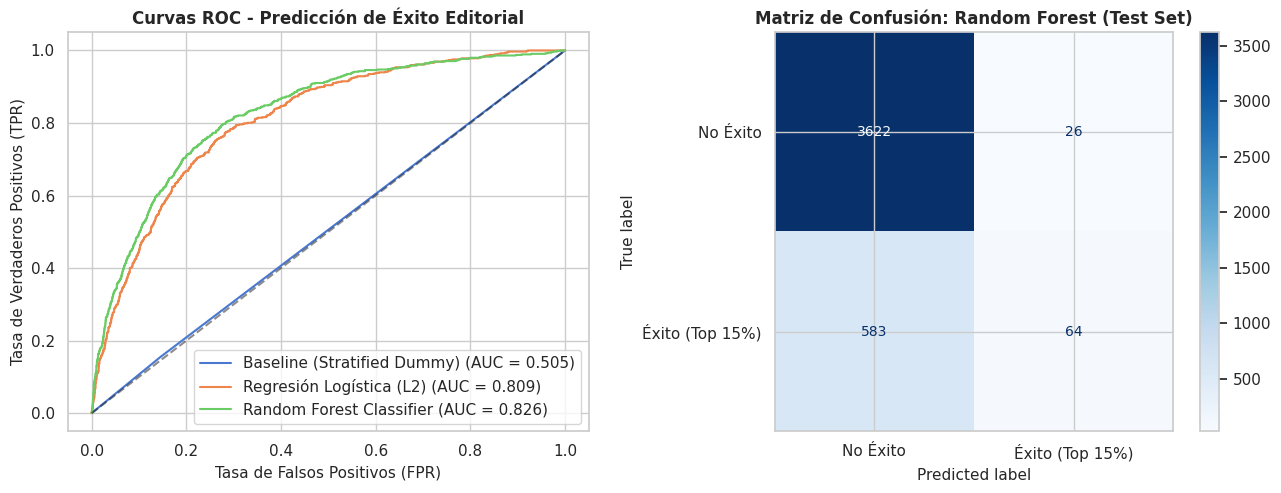


Reporte de Clasificación (Random Forest en Test Set):
              precision    recall  f1-score   support

    No Éxito       0.86      0.99      0.92      3648
       Éxito       0.71      0.10      0.17       647

    accuracy                           0.86      4295
   macro avg       0.79      0.55      0.55      4295
weighted avg       0.84      0.86      0.81      4295



/tmp/ipykernel_3964/1797170151.py:182: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_imp, x="Importancia", y="Feature", palette="viridis")


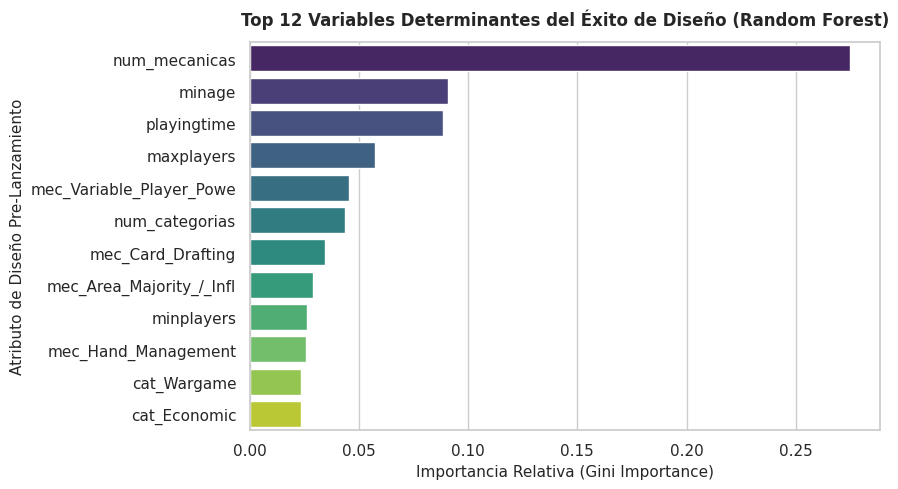

In [ ]:
from modeling import evaluar_modelos

resultados_modelado = evaluar_modelos(df)
plt.show()


## Conclusiones del trabajo

### Qué aprendimos

1. **El diseño aporta una señal, pero no decide solo.**
   El modelo de Gradient Boosting alcanza un $R^2 = 0.276$ y un MAE de 0.179 en el conjunto de prueba. Esto significa que las variables estructurales ayudan a estimar la recepción crítica, pero todavía queda una parte mayoritaria explicada por factores que no están en los datos.
2. **El potencial de entrar al top 15% puede ordenarse mejor que al azar.**
   Random Forest obtiene ROC-AUC = 0.832 y Average Precision = 0.474. Average Precision es especialmente importante porque solo el 15% de los casos pertenece a la clase positiva. El modelo sirve para priorizar prototipos, no para aprobar automáticamente una producción.
3. **La duración y la complejidad representan un trade-off editorial.**
   El gráfico de dispersión muestra cómo los diseños largos y densos conviven con distintos niveles de adopción. Un producto puede ser atractivo para un público experto y, al mismo tiempo, tener una audiencia minoritaria para retail.
4. **Los tópicos describen lenguajes de diseño diferentes.**
   NMF encuentra vocabularios asociados con construcción urbana, guerra, cartas, dados y colocación de losetas. Son agrupaciones exploratorias que ayudan a comparar posicionamientos, no categorías objetivas ni relaciones causales.
5. **La matriz de oportunidad convierte datos en una lista de investigación.**
   La combinación de calificación crítica y demanda relativa puede ayudar a priorizar licencias, localizaciones o reimpresiones. Antes de decidir, hay que sumar precio, derechos, costos, producción, distribución y validación comercial.

### Limitaciones

- BoardGameGeek representa principalmente a aficionados y no a todo el mercado retail.
- La fuente es un corte temporal de enero de 2022.
- El dataset no contiene arte, componentes, precio, marketing, distribución ni resultados financieros.
- Las asociaciones descriptivas no prueban causalidad.
- La importancia de variables de Random Forest es útil para interpretar el modelo, pero no equivale a un efecto causal.

### Recomendación final

Usar el pipeline como un **filtro inicial de decisión**: primero identificar perfiles y nichos prometedores, después validar con investigación de mercado, prototipos, costos y pruebas con público objetivo.